# 第 5 章 马尔科夫链蒙特卡罗 — 代码实验

对照教材：Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》Ch.3；Dunn & Shultis《Exploring Monte Carlo Methods》§6.1。

五个实验对应正文五条主线：**平稳分布**（§3.1）、**Metropolis 离散版**（§3.2）、**Metropolis 连续版与步长**（§3.2）、**Metropolis–Hastings 非对称校正**（§3.6）、**Ising 模型相变**（§3.4–3.5）。所有图保存为 `out-5-M.png`。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch05")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2024)
print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 股票市场链收敛到平稳分布（S&M §3.1）

三态链（up/same/down），转移矩阵见正文。理论平稳分布 \(\pi=[37,34,41]/112\approx[0.3304,0.3036,0.3661]\)（S&M 式 3.7）。看 \(p_t=p_0P^t\) 如何收敛，并用次特征值（谱隙）解释收敛速率。

In [2]:
P = np.array([[0.3, 0.2, 0.5],
              [0.4, 0.3, 0.3],
              [0.3, 0.4, 0.3]])     # 行:今天 up/same/down；列:明天
pi_exact = np.array([37, 34, 41]) / 112
w, V = np.linalg.eig(P.T)           # 左特征向量 -> 转置的右特征
k = np.argmin(np.abs(w - 1))
pi_eig = np.real(V[:, k]); pi_eig = pi_eig / pi_eig.sum()
print(f"解析  pi = {pi_exact.round(6)}")
print(f"特征向量 pi = {pi_eig.round(6)}")

p0 = np.array([1.0, 0, 0])          # 从 up 出发
diffs = []
for t in range(1, 26):
    pt = p0 @ np.linalg.matrix_power(P, t)
    diffs.append(np.linalg.norm(pt - pi_exact))
print(f"p10 = {(p0 @ np.linalg.matrix_power(P,10)).round(6)}  (S&M p10 同值)")
lam2 = np.sort(np.abs(w))[-2]
print(f"|次特征值| = {lam2:.4f}，相邻步收敛比 diff(t+1)/diff(t) -> {lam2:.4f}")

解析  pi = [0.330357 0.303571 0.366071]
特征向量 pi = [0.330357 0.303571 0.366071]
p10 = [0.330357 0.303571 0.366071]  (S&M p10 同值)
|次特征值| = 0.1414，相邻步收敛比 diff(t+1)/diff(t) -> 0.1414


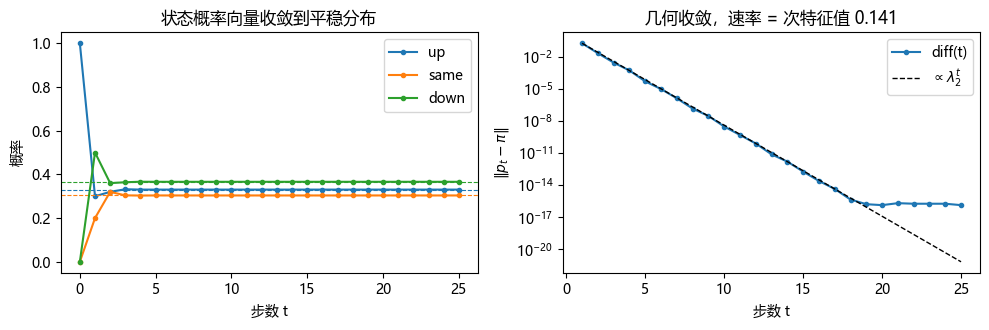

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
pt = np.array([p0 @ np.linalg.matrix_power(P, t) for t in range(26)])
for j, lab in enumerate(["up", "same", "down"]):
    ax[0].plot(pt[:, j], "-o", ms=3, label=lab)
    ax[0].axhline(pi_exact[j], ls="--", lw=0.8, color=f"C{j}")
ax[0].set_xlabel("步数 t"); ax[0].set_ylabel("概率"); ax[0].legend()
ax[0].set_title("状态概率向量收敛到平稳分布")
ax[1].semilogy(range(1, 26), diffs, "o-", ms=3, label="diff(t)")
ax[1].semilogy(range(1, 26), diffs[0]*lam2**np.arange(25), "k--", lw=1,
               label=r"$\propto\lambda_2^t$")
ax[1].set_xlabel("步数 t"); ax[1].set_ylabel(r"$\|p_t-\pi\|$"); ax[1].legend()
ax[1].set_title(f"几何收敛，速率 = 次特征值 {lam2:.3f}")
fig.tight_layout(); save(fig, "out-5-1.png"); plt.show()

## 实验 2 Metropolis 抽骰子和分布（S&M §3.2.1）

状态空间 {2,…,12}，目标 \(f(x)=\) 骰子和的分布 ×36。**最小邻域**提议：\(x\pm1\) 等可能；接受率 \(h=\min(1,f(y)/f(x))\)。样本强相关但统计正确。

In [4]:
f = np.array([0,0,1,2,3,4,5,6,5,4,3,2,1])  # f[2..12]
nTrials = 200_000
x = 5
chain = np.empty(nTrials, dtype=int)
for i in range(nTrials):
    y = x + (1 if rng.random() < 0.5 else -1)
    y = min(max(y, 2), 12)                    # 边界自环
    h = min(1.0, f[y] / f[x])
    if rng.random() < h:
        x = y
    chain[i] = x
emp = np.bincount(chain, minlength=13)[2:13] / nTrials
theo = f[2:13] / f.sum()
print("x        :", np.arange(2, 13))
print("MCMC 频率:", emp.round(4))
print("理论频率 :", theo.round(4))
print("最大偏差 :", np.abs(emp - theo).max().round(5))

x        : [ 2  3  4  5  6  7  8  9 10 11 12]
MCMC 频率: [0.0263 0.0537 0.0813 0.1098 0.1368 0.1649 0.139  0.1134 0.0873 0.0582
 0.0293]
理论频率 : [0.0278 0.0556 0.0833 0.1111 0.1389 0.1667 0.1389 0.1111 0.0833 0.0556
 0.0278]
最大偏差 : 0.00398


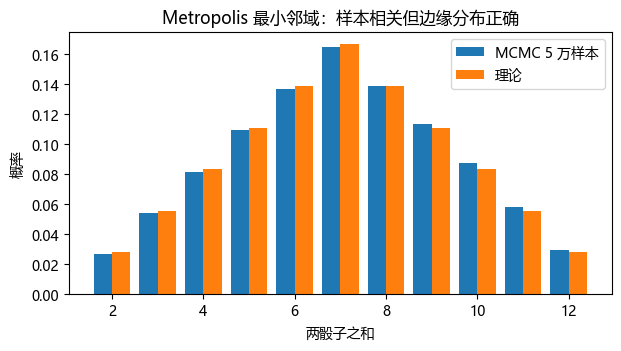

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(np.arange(2, 13) - 0.2, emp, width=0.4, label="MCMC 5 万样本")
ax.bar(np.arange(2, 13) + 0.2, theo, width=0.4, label="理论")
ax.set_xlabel("两骰子之和"); ax.set_ylabel("概率"); ax.legend()
ax.set_title("Metropolis 最小邻域：样本相关但边缘分布正确")
save(fig, "out-5-2.png"); plt.show()

## 实验 3 连续 Metropolis：双势阱与步长（S&M §3.2，D&S §6.1.4）

目标 \(\pi(x)\propto e^{-(x^2-4)^2/2}\)（双峰 ±2）。随机游走提议 \(x'=x+\sigma\varepsilon\)，对称 → 接受率 \(\min(1,\pi(y)/\pi(x))\)。步长太小粘在单峰，太大拒绝率高——**步长是连续 Metropolis 的核心调节参数**。

In [6]:
def metropolis_1d(n, sigma, x0=0.0):
    x, chain = x0, np.empty(n)
    for i in range(n):
        y = x + sigma * rng.standard_normal()
        logh = -0.5 * ((y**2 - 4)**2 - (x**2 - 4)**2)
        if np.log(rng.random()) < logh:
            x = y
        chain[i] = x
    return chain

n = 60_000
res = {s: metropolis_1d(n, s) for s in (0.5, 3.0)}
for s, c in res.items():
    right = (c > 0).mean()
    crossings = np.mean(np.abs(np.diff(np.sign(c))) > 0) * 1000
    print(f"σ={s}: 右峰占比 {right:.3f}（理论 0.5），每千步过零 {crossings:.1f} 次")

σ=0.5: 右峰占比 0.732（理论 0.5），每千步过零 0.2 次
σ=3.0: 右峰占比 0.510（理论 0.5），每千步过零 48.3 次


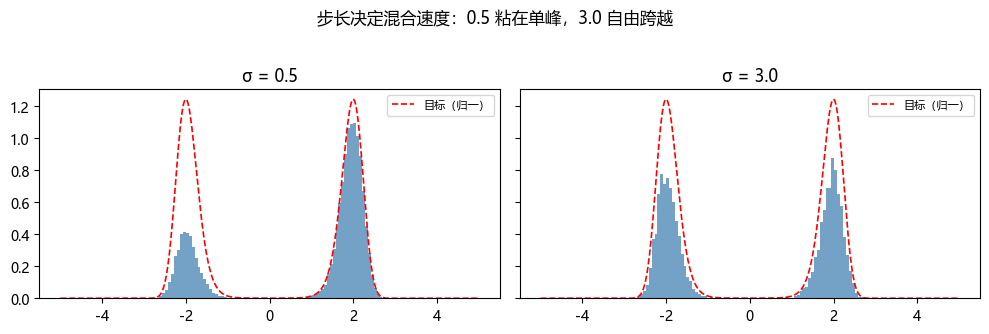

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
xx = np.linspace(-5, 5, 500)
dens = np.exp(-0.5 * (xx**2 - 4)**2)
for ax, (s, c) in zip(axes, res.items()):
    ax.hist(c, bins=80, density=True, color="steelblue", alpha=0.75)
    ax.plot(xx, dens / dens.sum() * 80, "r--", lw=1.2, label="目标（归一）")
    ax.set_title(f"σ = {s}"); ax.legend(fontsize=8)
fig.suptitle("步长决定混合速度：0.5 粘在单峰，3.0 自由跨越", y=1.03)
fig.tight_layout(); save(fig, "out-5-3.png"); plt.show()

## 实验 4 Metropolis–Hastings：忘记非对称校正的后果（S&M §3.6）

目标：半正态（均值为 \(\sqrt{2/\pi}pprox 0.798\)） \(f(x)=e^{-x^2/2},\ x>0\)。提议：\(x'\sim Exp(1)\)（独立提议、**非对称**：\(q(x'|x)=e^{-x'}\)，\(q(x|x')=e^{-x}\)，比值 \(e^{x'-x}\)）。正确 MH 接受率 \(\min\left(1,\frac{f(x')q(x|x')}{f(x)q(x'|x)}\right)\)；忘掉 \(q\) 比值就是普通 Metropolis，结果系统性偏离。

In [8]:
def mh_halfnormal(n, correct=True):
    x, out, acc = 1.0, np.empty(n), 0
    for i in range(n):
        xp = rng.exponential()                    # 提议 Exp(1)
        if correct:
            logh = -0.5*xp*xp + 0.5*x*x + (xp - x)  # q(x|x')/q(x'|x) = e^{x'-x}
        else:
            logh = -0.5*xp*xp + 0.5*x*x           # 忘掉 q 比值
        if np.log(rng.random()) < logh:
            x, acc = xp, acc + 1
        out[i] = x
    return out, acc / n

n = 120_000
c_ok,  r_ok  = mh_halfnormal(n, True)
c_bad, r_bad = mh_halfnormal(n, False)
mean_theo = np.sqrt(2 / np.pi)                    # 半正态均值 = √(2/π) ≈ 0.7979
print(f"理论均值 {mean_theo:.4f}")
print(f"正确 MH : {c_ok.mean():.4f}（接受率 {r_ok:.2f}）")
print(f"错误 MH : {c_bad.mean():.4f}")

理论均值 0.7979
正确 MH : 0.7994（接受率 0.84）
错误 MH : 0.5269


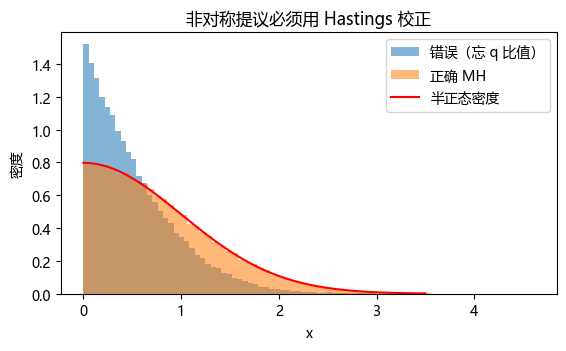

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
xx = np.linspace(0, 3.5, 400)
pdf = np.exp(-xx**2 / 2) / np.sqrt(np.pi / 2)   # 半正态归一：∫₀^∞ e^{-x²/2}dx = √(π/2)
ax.hist(c_bad, bins=70, density=True, alpha=0.55, label="错误（忘 q 比值）")
ax.hist(c_ok,  bins=70, density=True, alpha=0.55, label="正确 MH")
ax.plot(xx, pdf, "r-", lw=1.5, label="半正态密度")
ax.set_xlabel("x"); ax.set_ylabel("密度"); ax.legend()
ax.set_title("非对称提议必须用 Hastings 校正")
save(fig, "out-5-4.png"); plt.show()

## 实验 5 Ising 模型相变（S&M §3.4–3.5）

2D Ising（周期边界，\(E=-\sum s_is_j\)，J=1，自然单位 \(k_B=1\)）。单点翻转 Metropolis：\(\Delta E\le0\) 接受，否则概率 \(e^{-\Delta E/T}\)。扫温度看磁矩 \(\langle M\rangle\)——理论临界温度 \(T_c=2/\ln(1+\sqrt2)\approx 2.269\)。

In [10]:
def ising_metro(L, T, burn, meas):
    s = rng.choice([-1, 1], (L, L))
    for _ in range(burn):
        ising_sweep(s, L, T)
    m_sum = 0.0
    for _ in range(meas):
        ising_sweep(s, L, T)
        m_sum += abs(s.sum())
    return m_sum / meas / (L * L)

def ising_sweep(s, L, T):
    for _ in range(L * L):                    # 一次 sweep = L² 次翻转尝试
        i, j = rng.integers(L), rng.integers(L)
        # 周期边界邻居能量差：翻转会改变 4 个键
        nb = s[(i+1) % L, j] + s[(i-1) % L, j] + s[i, (j+1) % L] + s[i, (j-1) % L]
        dE = 2 * s[i, j] * nb
        if dE <= 0 or rng.random() < np.exp(-dE / T):
            s[i, j] = -s[i, j]

Ts = np.linspace(1.2, 3.6, 13)
mags = [ising_metro(16, T, burn=2000, meas=400) for T in Ts]
Tc = 2 / np.log(1 + np.sqrt(2))
for T, m in zip(Ts, mags):
    print(f"T = {T:.2f}   |M|/spin = {m:.3f}")
print(f"理论临界温度 Tc = {Tc:.3f}")

T = 1.20   |M|/spin = 0.997
T = 1.40   |M|/spin = 0.992
T = 1.60   |M|/spin = 0.981
T = 1.80   |M|/spin = 0.956
T = 2.00   |M|/spin = 0.912
T = 2.20   |M|/spin = 0.807
T = 2.40   |M|/spin = 0.465
T = 2.60   |M|/spin = 0.226
T = 2.80   |M|/spin = 0.203
T = 3.00   |M|/spin = 0.218
T = 3.20   |M|/spin = 0.140
T = 3.40   |M|/spin = 0.152
T = 3.60   |M|/spin = 0.137
理论临界温度 Tc = 2.269


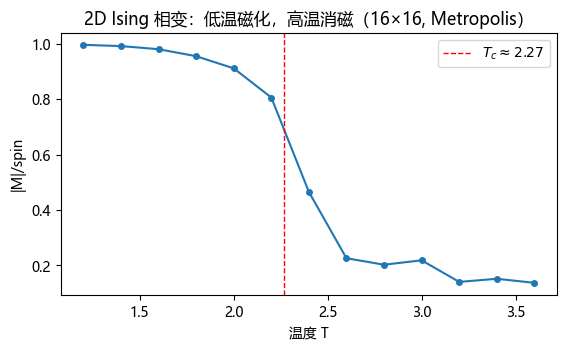

In [11]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(Ts, mags, "o-", ms=4)
ax.axvline(Tc, color="r", ls="--", lw=1, label=f"$T_c\\approx{Tc:.2f}$")
ax.set_xlabel("温度 T"); ax.set_ylabel("|M|/spin")
ax.set_title("2D Ising 相变：低温磁化，高温消磁（16×16, Metropolis）")
ax.legend(); save(fig, "out-5-5.png"); plt.show()